In [6]:
import pandas as pd

# Load dataset
df = pd.read_csv("heart_cleaned.csv")

# Columns to check for outliers
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]

# Function to remove outliers using IQR
def remove_outliers_iqr(data, columns):
    for col in columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Keep only rows within bounds
        data = data[(data[col] >= lower_bound) & (data[col] <= upper_bound)]
    return data

# Apply outlier removal
df_cleaned = remove_outliers_iqr(df, num_cols)

print("Original shape:", df.shape)
print("Cleaned shape:", df_cleaned.shape)

#Save the cleaned dataset
df_cleaned.to_csv("heart_cleaned_no_outliers.csv", index=False)

Original shape: (1025, 14)
Cleaned shape: (889, 14)


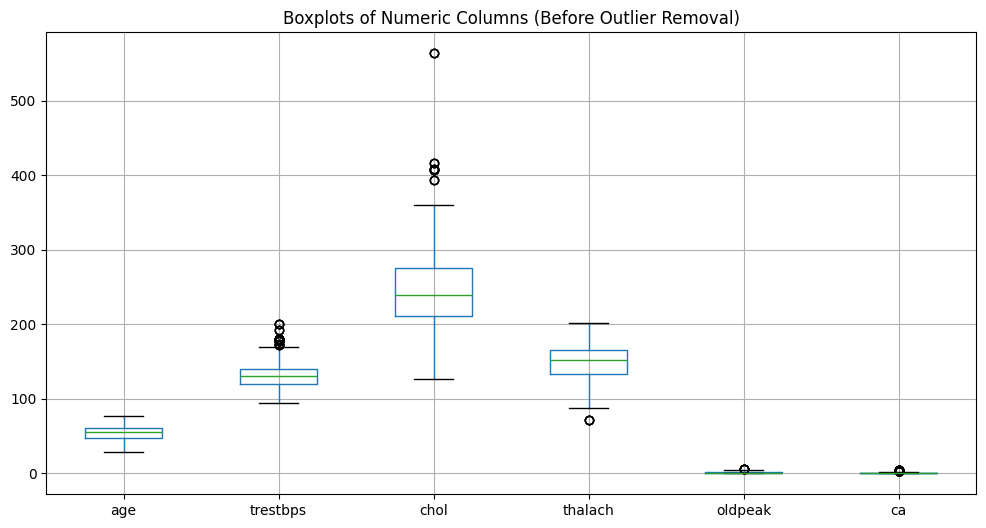

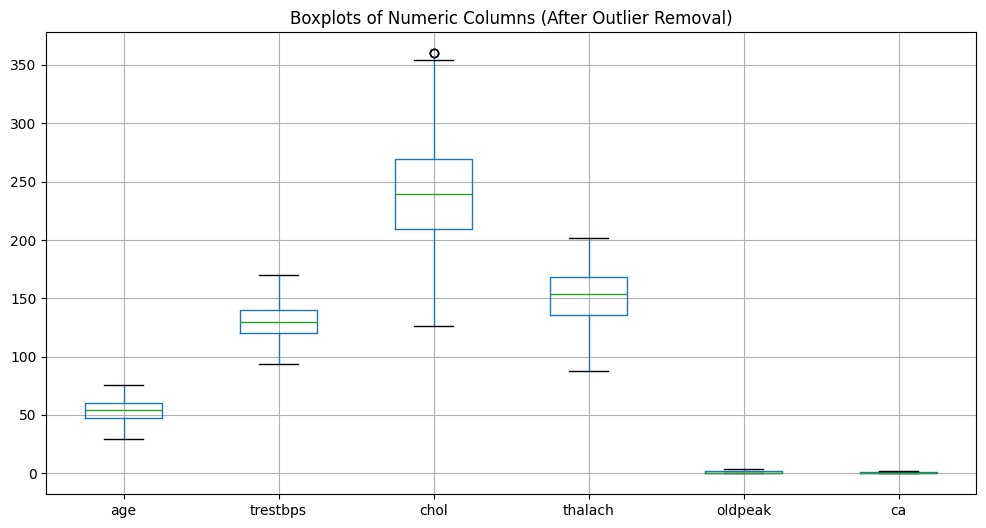

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Before cleaning
plt.figure(figsize=(12,6))
df[num_cols].boxplot()
plt.title("Boxplots of Numeric Columns (Before Outlier Removal)")
plt.show()

# After cleaning
plt.figure(figsize=(12,6))
df_cleaned[num_cols].boxplot()
plt.title("Boxplots of Numeric Columns (After Outlier Removal)")
plt.show()